# **Retail Customer Segmentation and High Value Customer Prediction**

### **Problem Statement**
A retail company wants to understand its customers better. The company has collected customer profile, website activity, purchase behavior, and campaign response data. Our task is to analyze the dataset, identify meaningful customer groups, predict customer Value, and provide simple business recommendations.

In [229]:
# upload dataset
from google.colab import files
uploaded = files.upload()

Saving retail_customer_project_dataset.csv to retail_customer_project_dataset (2).csv


### **Part A: Data Loading and Exploration**

In [230]:
# import required libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

In [231]:
# Load the dataset and display the first 10 rows.
df = pd.read_csv('retail_customer_project_dataset.csv')
df.head(10)

,CustomerID,Age,Gender,AnnualIncome,SpendingScore,WebsiteVisitsPerMonth,AvgSessionMinutes,PreviousPurchases,DiscountUsed,EmailOpened,MembershipYears,PurchaseAmount,CampaignResponse,HighValueCustomer
0,C1000,37,Female,49550.0,78,9,10.3,2,Yes,Yes,1.8,388.52,Yes,No
1,C1001,23,Male,51094.0,100,11,6.8,17,Yes,Yes,4.0,708.64,Yes,Yes
2,C1002,42,Female,84127.0,100,10,7.7,15,Yes,Yes,3.4,686.87,Yes,Yes
3,C1003,44,Male,26194.0,100,7,8.9,10,Yes,Yes,6.8,544.05,Yes,Yes
4,C1004,18,Male,18000.0,62,5,6.0,4,No,Yes,0.9,328.02,Yes,No
5,C1005,20,Male,52014.0,100,5,8.8,5,Yes,Yes,0.8,485.17,Yes,No
6,C1006,35,Male,98438.0,100,7,2.6,4,Yes,Yes,1.3,583.93,Yes,Yes
7,C1007,31,Female,54254.0,82,8,8.7,7,No,No,1.8,445.44,Yes,No
8,C1008,34,Female,65851.0,100,5,1.5,6,Yes,Yes,1.1,497.03,Yes,No
9,C1009,25,Female,85063.0,100,7,7.0,4,Yes,Yes,0.9,566.25,Yes,No


In [232]:
# Print dataset shape, column names, data types, and missing value count.

print('Dataset shape:', df.shape)
print('\nColumn names:\n', df.columns.tolist())
print('\nData types:\n', df.dtypes)
print('\nMissing value count:\n', df.isnull().sum())

Dataset shape: (600, 14)

Column names:
 ['CustomerID', 'Age', 'Gender', 'AnnualIncome', 'SpendingScore', 'WebsiteVisitsPerMonth', 'AvgSessionMinutes', 'PreviousPurchases', 'DiscountUsed', 'EmailOpened', 'MembershipYears', 'PurchaseAmount', 'CampaignResponse', 'HighValueCustomer']

Data types:
 CustomerID                object
Age                        int64
Gender                    object
AnnualIncome             float64
SpendingScore              int64
WebsiteVisitsPerMonth      int64
AvgSessionMinutes        float64
PreviousPurchases          int64
DiscountUsed              object
EmailOpened               object
MembershipYears          float64
PurchaseAmount           float64
CampaignResponse          object
HighValueCustomer         object
dtype: object

Missing value count:
 CustomerID               0
Age                      0
Gender                   0
AnnualIncome             6
SpendingScore            0
WebsiteVisitsPerMonth    0
AvgSessionMinutes        8
PreviousPurchase

In [233]:
# Check duplicate customer IDS
print("Duplicate Customer IDs:", df['CustomerID'].duplicated().sum())
print("Duplicate rows:", df.duplicated().sum())

Duplicate Customer IDs: 0
Duplicate rows: 0


In [234]:
# Find summary statistics for numerical columns.

df.describe().T

,count,mean,std,min,25%,50%,75%,max
Age,600.0,34.023333,10.108731,18.0,26.000,34.00,40.0000,65.00
AnnualIncome,594.0,67342.202020,22536.874364,18000.0,51999.000,67135.00,82697.7500,129540.00
SpendingScore,600.0,95.881667,9.850519,38.0,100.000,100.00,100.0000,100.00
WebsiteVisitsPerMonth,600.0,7.485000,2.951999,0.0,5.000,7.00,9.0000,18.00
AvgSessionMinutes,592.0,7.626014,2.356055,1.0,6.000,7.60,9.1000,17.50
PreviousPurchases,600.0,7.185000,3.502078,0.0,5.000,7.00,9.0000,19.00
MembershipYears,600.0,2.399833,1.705256,0.1,1.175,2.10,3.2000,8.00
PurchaseAmount,600.0,540.854083,84.555524,206.7,494.165,545.01,596.0825,763.62


In [235]:
# Count customers by Gender, CampaignResponse, and HighValueCustomer.
# findings: CampaignResponse is highly imbalanced. more than 91% of customers responded to the campaigns

print('Customers by Gender:')
print(df['Gender'].value_counts())
print('\nCustomers by CampaignResponse:')
print(df['CampaignResponse'].value_counts())
print('\nCustomers by HighValueCustomer:')
print(df['HighValueCustomer'].value_counts())


Customers by Gender:
Gender
Female    322
Male      278
Name: count, dtype: int64

Customers by CampaignResponse:
CampaignResponse
Yes    548
No      52
Name: count, dtype: int64

Customers by HighValueCustomer:
HighValueCustomer
No     311
Yes    289
Name: count, dtype: int64


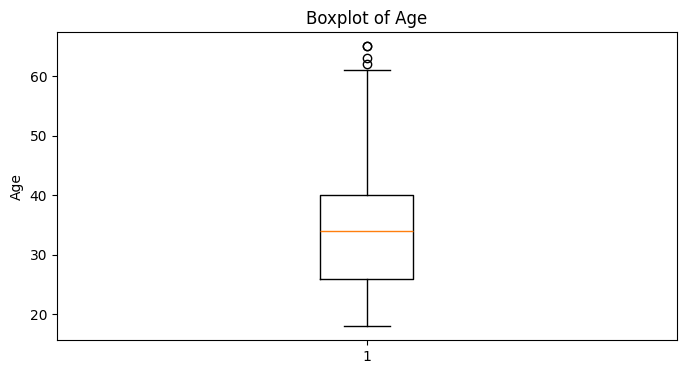

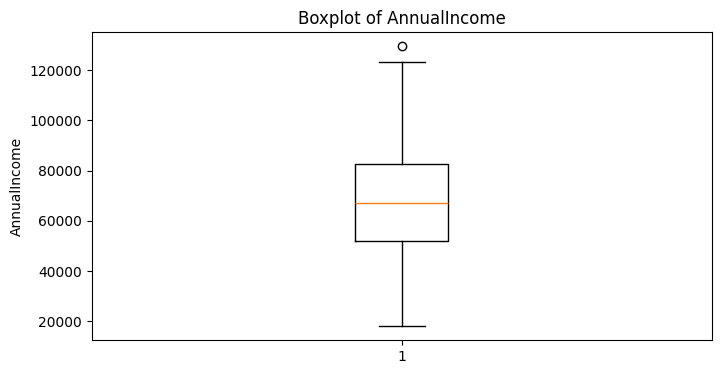

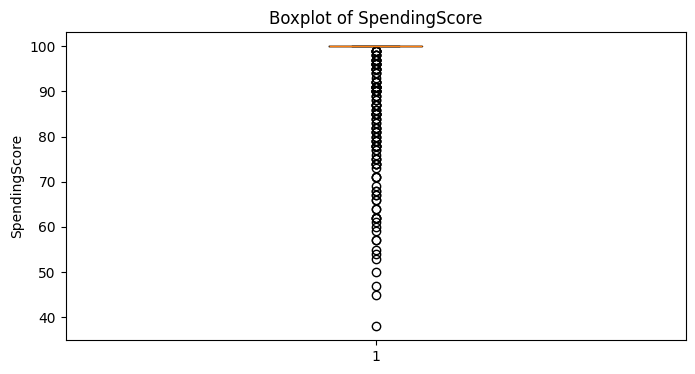

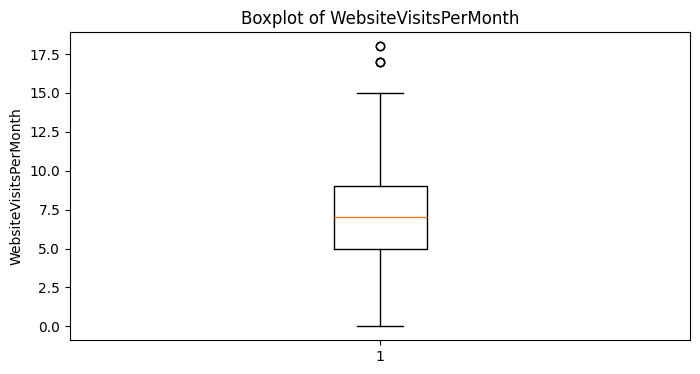

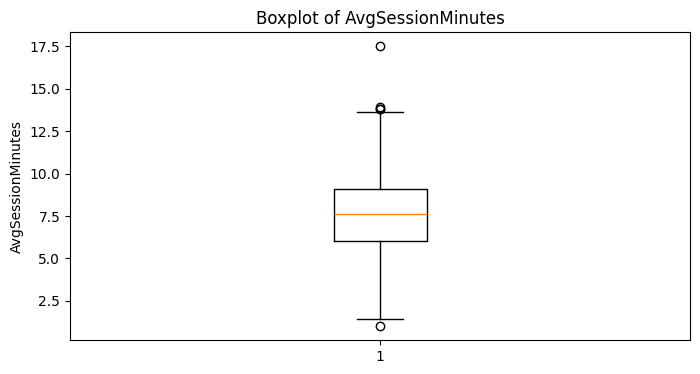

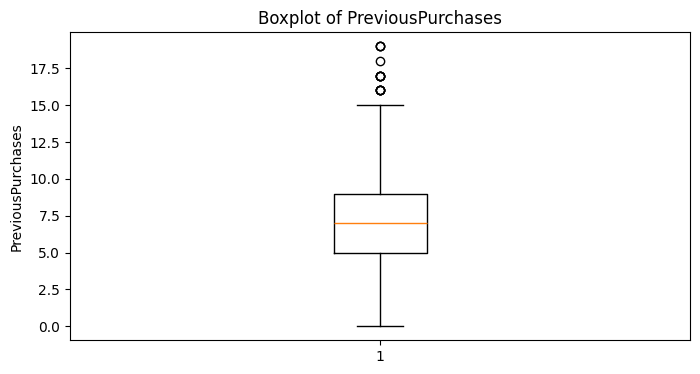

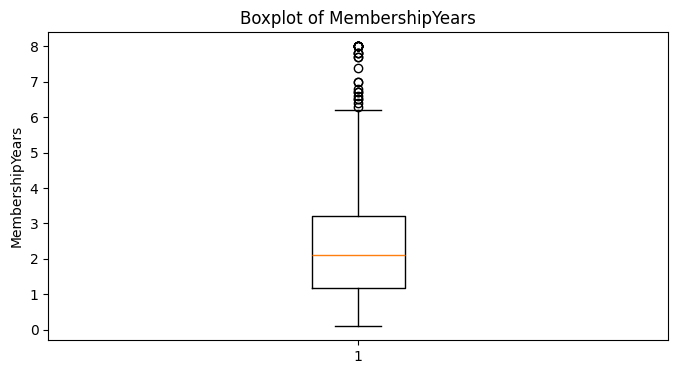

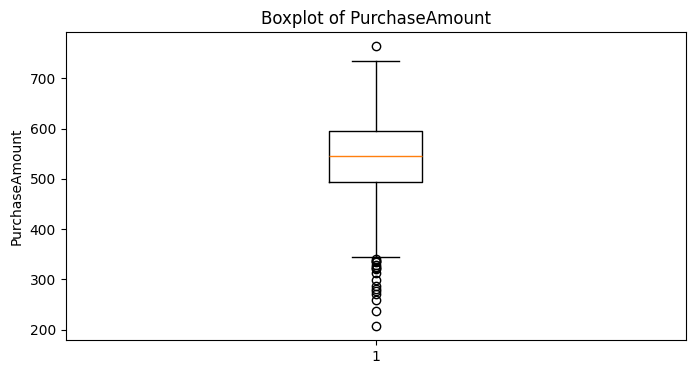


Age
Q1: 26.00
Q3: 40.00
IQR: 14.00
Lower Bound: 5.00
Upper Bound: 61.00
Number of Outliers: 4

AnnualIncome
Q1: 51999.00
Q3: 82697.75
IQR: 30698.75
Lower Bound: 5950.88
Upper Bound: 128745.88
Number of Outliers: 1

SpendingScore
Q1: 100.00
Q3: 100.00
IQR: 0.00
Lower Bound: 100.00
Upper Bound: 100.00
Number of Outliers: 141

WebsiteVisitsPerMonth
Q1: 5.00
Q3: 9.00
IQR: 4.00
Lower Bound: -1.00
Upper Bound: 15.00
Number of Outliers: 5

AvgSessionMinutes
Q1: 6.00
Q3: 9.10
IQR: 3.10
Lower Bound: 1.35
Upper Bound: 13.75
Number of Outliers: 5

PreviousPurchases
Q1: 5.00
Q3: 9.00
IQR: 4.00
Lower Bound: -1.00
Upper Bound: 15.00
Number of Outliers: 14

MembershipYears
Q1: 1.18
Q3: 3.20
IQR: 2.03
Lower Bound: -1.86
Upper Bound: 6.24
Number of Outliers: 26

PurchaseAmount
Q1: 494.17
Q3: 596.08
IQR: 101.92
Lower Bound: 341.29
Upper Bound: 748.96
Number of Outliers: 18


In [236]:
# Identify outliers using simple plots.

# numerical columns
numerical_cols = list(df.select_dtypes(include=np.number).columns)

# Outlier Detection using boxplots
for col in numerical_cols:
    plt.figure(figsize=(8, 4))
    plt.boxplot(df[col].dropna())
    plt.title(f'Boxplot of {col}')
    plt.ylabel(col)
    plt.show()

# Outlier Calculation as per statistical formula
for col in numerical_cols:

    data = df[col].dropna()

    Q1 = data.quantile(0.25)
    Q3 = data.quantile(0.75)
    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outliers = data[(data < lower_bound) | (data > upper_bound)]

    print(f"\n{col}")
    print(f"Q1: {Q1:.2f}")
    print(f"Q3: {Q3:.2f}")
    print(f"IQR: {IQR:.2f}")
    print(f"Lower Bound: {lower_bound:.2f}")
    print(f"Upper Bound: {upper_bound:.2f}")
    print(f"Number of Outliers: {len(outliers)}")

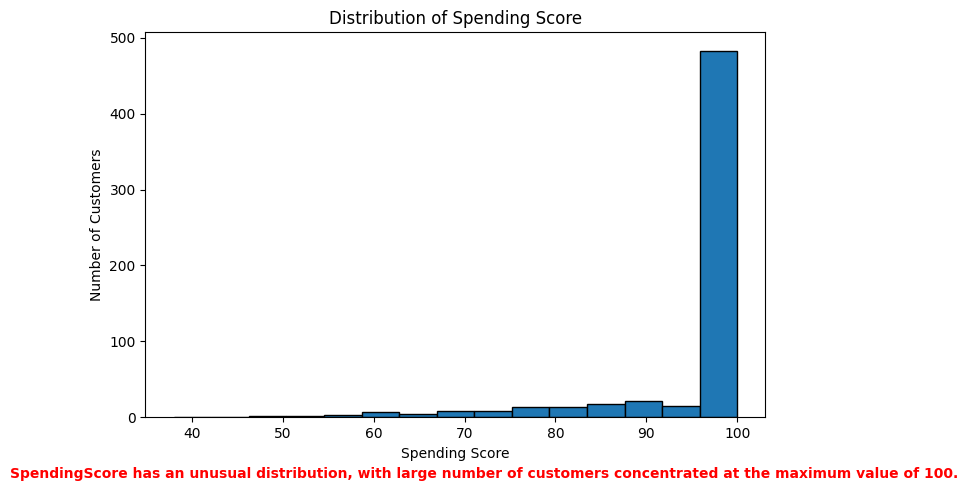

In [237]:
# Identify any unusual values
plt.figure(figsize=(8, 5))

plt.hist(df['SpendingScore'], bins=15, edgecolor='black')

plt.title('Distribution of Spending Score')
plt.xlabel('Spending Score')
plt.ylabel('Number of Customers')

plt.text(
    x=20,
    y=-80,
    s='SpendingScore has an unusual distribution, with large number of customers concentrated at the maximum value of 100.',
    fontsize=10,
    color='red',
    weight='bold'
)

plt.show()

### **Part B: Data Preprocessing**

In [238]:
# Separate numerical and categorical columns.

numerical_cols = df.select_dtypes(include=np.number).columns.tolist()

print("Numerical Columns:")
print(numerical_cols)

categorical_cols = df.select_dtypes(include='object').columns.tolist()

print("Categorical Columns:")
print(categorical_cols)

Numerical Columns:
['Age', 'AnnualIncome', 'SpendingScore', 'WebsiteVisitsPerMonth', 'AvgSessionMinutes', 'PreviousPurchases', 'MembershipYears', 'PurchaseAmount']
Categorical Columns:
['CustomerID', 'Gender', 'DiscountUsed', 'EmailOpened', 'CampaignResponse', 'HighValueCustomer']


In [239]:
# Handling Missing Values

df_processed = df.copy()

# Numerical missing values
df_processed['AnnualIncome'] = df_processed['AnnualIncome'].fillna(
    df_processed['AnnualIncome'].median()
)

df_processed['AvgSessionMinutes'] = df_processed['AvgSessionMinutes'].fillna(
    df_processed['AvgSessionMinutes'].median()
)

# Categorical missing value
df_processed['EmailOpened'] = df_processed['EmailOpened'].fillna(
    df_processed['EmailOpened'].mode()[0]    # we used [0] to get the first mode value in case there are multiple modes in the pandas series
)

In [240]:
# categorical encoding

# Gender encoding
df_processed['Gender'] = df_processed['Gender'].map({
    'Female': 0,
    'Male': 1
})

# Encode Yes/No variables
yes_no_cols = [
    'DiscountUsed',
    'EmailOpened',
    'CampaignResponse',
    'HighValueCustomer'
]

for col in yes_no_cols:
    df_processed[col] = df_processed[col].map({
        'No': 0,
        'Yes': 1
    })



In [241]:
# Scale numerical features using StandardScaler.

from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

df_scaled = df_processed.copy()

df_scaled[numerical_cols] = scaler.fit_transform(
    df_processed[numerical_cols]
)

df_scaled[numerical_cols].describe().T

,count,mean,std,min,25%,50%,75%,max
Age,600.0,-1.924387e-17,1.000834,-1.586421,-0.794366,-0.002310,0.591731,3.066905
AnnualIncome,600.0,-2.057613e-16,1.000834,-2.202190,-0.682140,-0.009156,0.681169,2.776156
SpendingScore,600.0,6.335673e-16,1.000834,-5.880905,0.418432,0.418432,0.418432,0.418432
WebsiteVisitsPerMonth,600.0,-9.769963e-17,1.000834,-2.537685,-0.842505,-0.164433,0.513640,3.564965
AvgSessionMinutes,600.0,4.322468e-16,1.000834,-2.833516,-0.695228,-0.010977,0.630510,4.222832
PreviousPurchases,600.0,1.154632e-16,1.000834,-2.053351,-0.624436,-0.052870,0.518696,3.376526
MembershipYears,600.0,-7.105427e-17,1.000834,-1.349799,-0.718869,-0.175976,0.469627,3.286803
PurchaseAmount,600.0,-7.046215e-16,1.000834,-3.955187,-0.552631,0.049191,0.653707,2.636750


In [242]:
# Explain why encoding and scaling are required before clustering and classification.

print("Machine-learning algorithms generally work with numerical data. \nIn our project we have K-Means, Logistic Regression, KNN, PCA algorithms. \nThese methods require numerical feature representations.\n\nWe scale numerical features because variables like AnnualIncome and WebsiteVisits differ in scale and AnnualIncome can have a large influence. \nScaling also prevents variables with large numerical values from dominating the clustering process")

Machine-learning algorithms generally work with numerical data. 
In our project we have K-Means, Logistic Regression, KNN, PCA algorithms. 
These methods require numerical feature representations.

We scale numerical features because variables like AnnualIncome and WebsiteVisits differ in scale and AnnualIncome can have a large influence. 
Scaling also prevents variables with large numerical values from dominating the clustering process


### **Part C: Exploratory Data Analysis and Visualization**

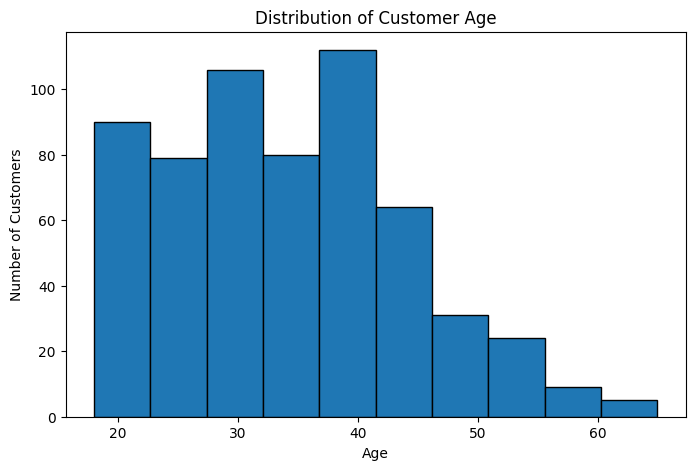

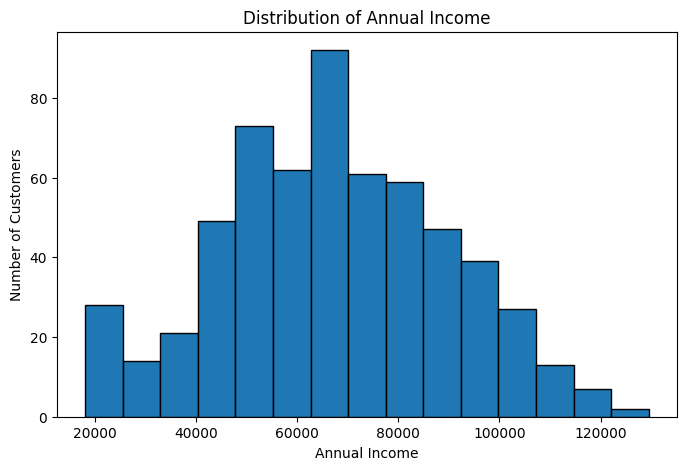

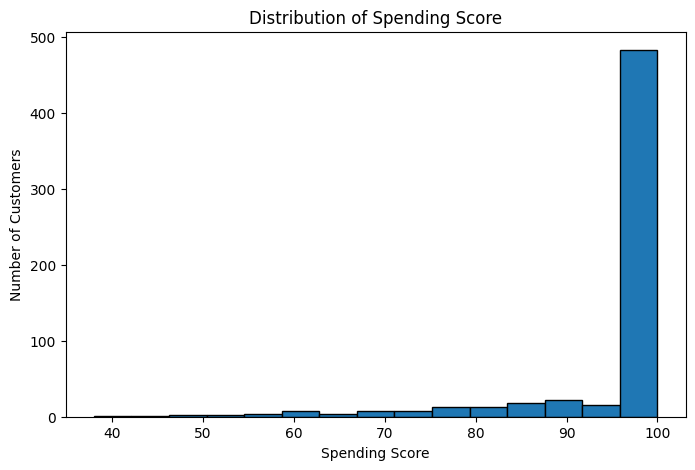

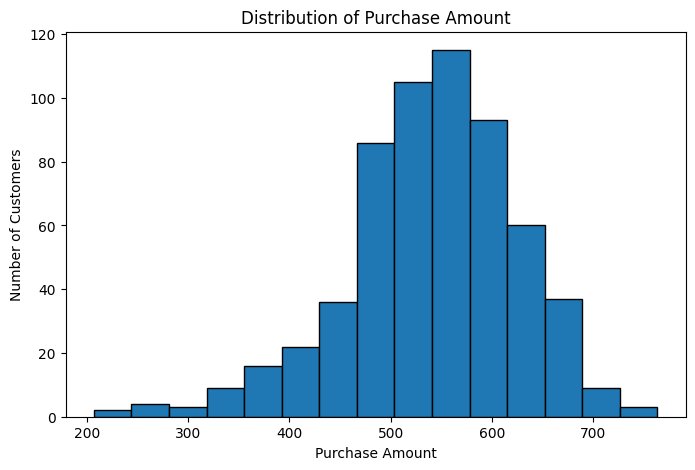

In [243]:
# Plot histograms for Age, AnnualIncome, SpendingScore, and PurchaseAmount.

# Age
plt.figure(figsize=(8, 5))

plt.hist(df['Age'].dropna(), bins=10, edgecolor='black')

plt.title('Distribution of Customer Age')
plt.xlabel('Age')
plt.ylabel('Number of Customers')

plt.show()

# AnnualIncome
plt.figure(figsize=(8, 5))

plt.hist(df['AnnualIncome'].dropna(), bins=15, edgecolor='black')

plt.title('Distribution of Annual Income')
plt.xlabel('Annual Income')
plt.ylabel('Number of Customers')

plt.show()

# SpendingScore
plt.figure(figsize=(8, 5))

plt.hist(df['SpendingScore'].dropna(), bins=15, edgecolor='black')

plt.title('Distribution of Spending Score')
plt.xlabel('Spending Score')
plt.ylabel('Number of Customers')

plt.show()

# PurchaseAmount
plt.figure(figsize=(8, 5))

plt.hist(df['PurchaseAmount'].dropna(), bins=15, edgecolor='black')

plt.title('Distribution of Purchase Amount')
plt.xlabel('Purchase Amount')
plt.ylabel('Number of Customers')

plt.show()

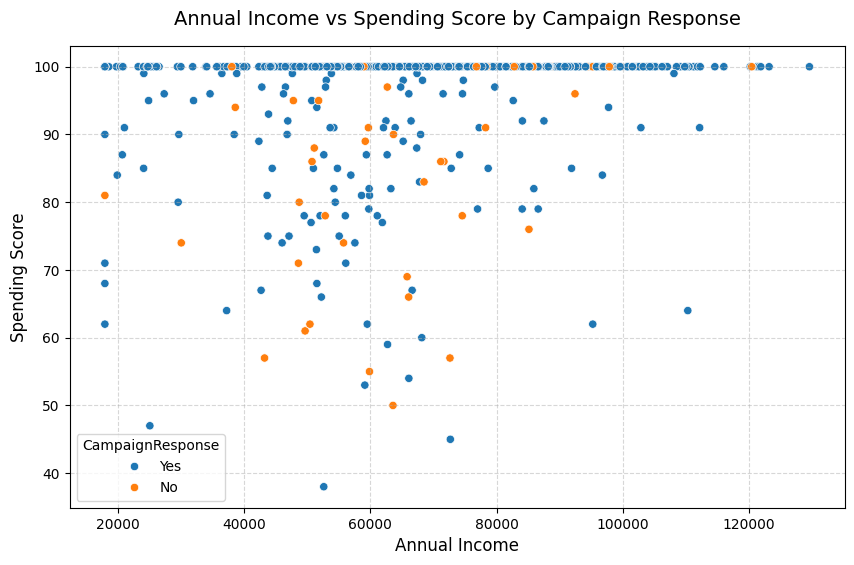

In [244]:
# scatter plot of AnnualIncome vs SpendingScore and color it by CampaignResponse.

import seaborn as sns

plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df,
    x='AnnualIncome',
    y='SpendingScore',
    hue='CampaignResponse',
)

plt.title('Annual Income vs Spending Score by Campaign Response', fontsize=14, pad=15)
plt.xlabel('Annual Income', fontsize=12)
plt.ylabel('Spending Score', fontsize=12)
plt.grid(axis='both', linestyle='--', alpha=0.5)

plt.show()

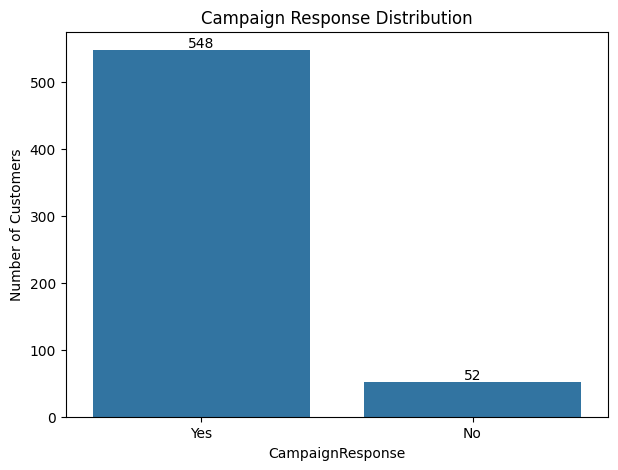

In [292]:
# bar chart for CampaignResponse counts.

plt.figure(figsize=(7, 5))

ax = sns.countplot(data=df, x='CampaignResponse')
ax.bar_label(ax.containers[0])

plt.title('Campaign Response Distribution')
plt.ylabel('Number of Customers')
plt.show()

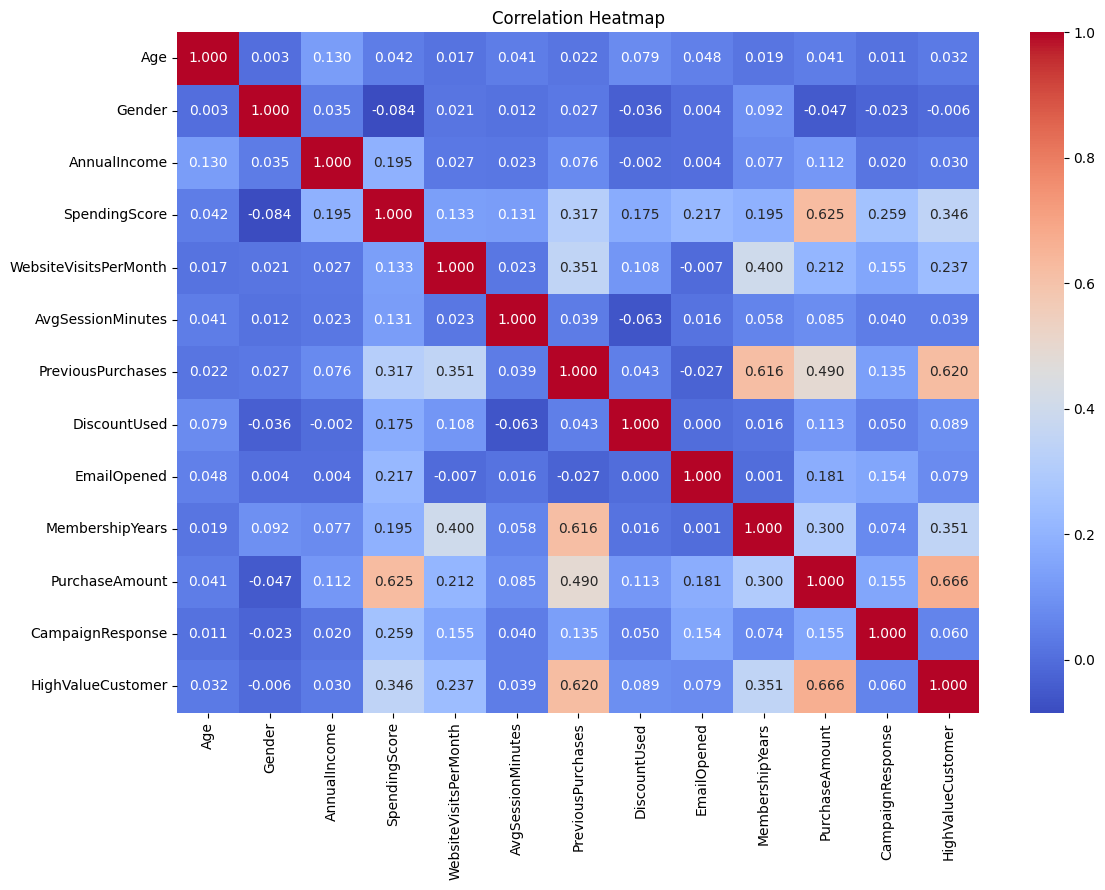

In [246]:
# correlation heatmap and identify at least three useful relationships.

# Selecting all analytical variables except CustomerID
correlation_cols = [
    'Age',
    'Gender',
    'AnnualIncome',
    'SpendingScore',
    'WebsiteVisitsPerMonth',
    'AvgSessionMinutes',
    'PreviousPurchases',
    'DiscountUsed',
    'EmailOpened',
    'MembershipYears',
    'PurchaseAmount',
    'CampaignResponse',
    'HighValueCustomer'
]

# correlation matrix
corr_matrix = df_processed[correlation_cols].corr()


plt.figure(figsize=(12, 9))

sns.heatmap(
    corr_matrix,
    annot=True,
    fmt='.3f',
    cmap='coolwarm',
)

plt.title('Correlation Heatmap')
plt.tight_layout()
plt.show()

In [247]:
# 3 useful relationships based on the correlation heatmap above

print("1. PurchaseAmount & HighValueCustomer: r = 0.666")
print("2. SpendingScore & PurchaseAmount: r = 0.625")
print("3. PreviousPurchases & HighValueCustomer: r = 0.620")


1. PurchaseAmount & HighValueCustomer: r = 0.666
2. SpendingScore & PurchaseAmount: r = 0.625
3. PreviousPurchases & HighValueCustomer: r = 0.620


In [248]:
# 5 observations from your plots.

print("1. Customers are mainly in the younger and middle-age bracket, with few customers above 50.")
print("\n2. AnnualIncome is broadly distributed, having most customers concentrated near the middle-income range. SpendingScore is highly concentrated at 100, making it an unusual for segmentation.")
print("\n3. There is no strong visible relationship between AnnualIncome and SpendingScore")
print("\n4. CampaignResponse is highly imbalanced, with 548 Yes vs 52 No responses (91.3% response rate).")
print("\n5. PurchaseAmount is strongly related with both SpendingScore (r = 0.625) and HighValueCustomer (r = 0.667). PreviousPurchases has a strong relationship with both MembershipYears (r = 0.616) and HighValueCustomer (r = 0.620)")

1. Customers are mainly in the younger and middle-age bracket, with few customers above 50.

2. AnnualIncome is broadly distributed, having most customers concentrated near the middle-income range. SpendingScore is highly concentrated at 100, making it an unusual for segmentation.

3. There is no strong visible relationship between AnnualIncome and SpendingScore

4. CampaignResponse is highly imbalanced, with 548 Yes vs 52 No responses (91.3% response rate).

5. PurchaseAmount is strongly related with both SpendingScore (r = 0.625) and HighValueCustomer (r = 0.667). PreviousPurchases has a strong relationship with both MembershipYears (r = 0.616) and HighValueCustomer (r = 0.620)


### **Part D: Customer Segmentation Using Clustering**

we excluded **CampaignResponse** and **HighValueCustomer** because they tell us whether the customer responded to a campaign or customer is classified as high-value. If we use them in clustering, the clusters could become influenced by those outcome variables. **Gender, DiscountUsed** and **EmailOpened** are also excluded from K-Means because they are categorical variables. Standard K-Means uses Euclidean distance and is better suited to continuous numerical features. Also it was observed during a previous trial run that including them didn't improve the cluster separation significantly.

In [275]:
# selecting clustering features ( we have excluded CustomerID as its a unique identifier. CampaignResponse and HighValueCustomer are also excluded as they are target labels.)
clustering_features = [
    'Age',
    'AnnualIncome',
    'SpendingScore',
    'WebsiteVisitsPerMonth',
    'AvgSessionMinutes',
    'PreviousPurchases',
    'MembershipYears',
    'PurchaseAmount'

]

X_cluster = df_scaled[clustering_features]

print("Clustering features:")
print(clustering_features)

print("\nClustering data shape:", X_cluster.shape)

Clustering features:
['Age', 'AnnualIncome', 'SpendingScore', 'WebsiteVisitsPerMonth', 'AvgSessionMinutes', 'PreviousPurchases', 'MembershipYears', 'PurchaseAmount']

Clustering data shape: (600, 8)


In [276]:
# Run K-Means for K = 1 to 10

from sklearn.cluster import KMeans

inertia = []

for k in range(1, 11):
    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    kmeans.fit(X_cluster)
    inertia.append(kmeans.inertia_)

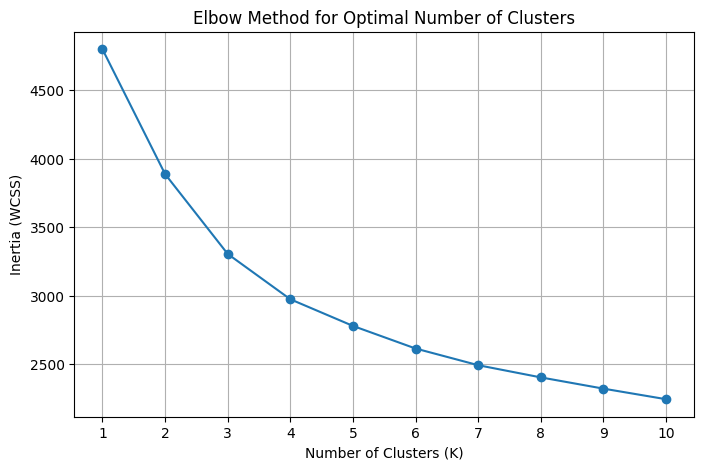

In [277]:
# elbow method for k = 1 to 10 to identify a suitable k.

plt.figure(figsize=(8, 5))

plt.plot(
    range(1, 11),
    inertia,
    marker='o'
)

plt.title('Elbow Method for Optimal Number of Clusters')
plt.xlabel('Number of Clusters (K)')
plt.ylabel('Inertia (WCSS)')
plt.xticks(range(1, 11))
plt.grid(True)

plt.show()

In [278]:
# Fit K-Means with K=3 as it seems to be the elbow point

kmeans = KMeans(
    n_clusters=3,
    random_state=42,
    n_init=10
)

cluster_labels = kmeans.fit_predict(X_cluster)

df_processed['Cluster'] = cluster_labels

# check cluster size
df_processed['Cluster'].value_counts().sort_index()

,count
Cluster,
0,77
1,344
2,179


In [279]:
# silhouette score for the selected k.

from sklearn.metrics import silhouette_score

silhouette_avg = silhouette_score(
    X_cluster,
    cluster_labels
)

print("Silhouette Score:", round(silhouette_avg, 4))

Silhouette Score: 0.1817


The elbow method suggested 3 clusters, but the silhouette score of 0.1817 shows weak cluster separation. Therefore, the 3 segments can be interpreted as broad customer segments rather than distinct customer types.

In [281]:
# Apply one additional clustering method: Agglomerative Clustering

from sklearn.cluster import AgglomerativeClustering



agglo = AgglomerativeClustering(
    n_clusters=3,
    linkage='ward'
)

agglo_labels = agglo.fit_predict(X_cluster)

agglo_counts = pd.Series(agglo_labels).value_counts().sort_index()

print("Agglomerative Cluster Sizes:")
print(agglo_counts)


agglo_silhouette = silhouette_score(
    X_cluster,
    agglo_labels
)

print(
    "Agglomerative Silhouette Score:",
    round(agglo_silhouette, 4)
)

Agglomerative Cluster Sizes:
0    287
1    253
2     60
Name: count, dtype: int64
Agglomerative Silhouette Score: 0.1404


In [284]:
# Comparing the clustering methods and describing the customer segments.

print("K-Means with three clusters achieved the highest silhouette score (0.1644) among the evaluated methods.\nAlthough the score indicates moderate overlap between customer groups, K-Means provided the most practical segmentation compared with Agglomerative Clustering (0.1404)")
print("="*70)

# Add the final K-Means cluster labels to df_processed
df_processed['Cluster'] = cluster_labels

# Profile numerical features by cluster
cluster_profile = df_processed.groupby('Cluster')[clustering_features].mean().round(2)

print(cluster_profile)

print("="*70)
print("Customer Segments")

print("Cluster 0 — Low-Engagement Customers: Customers with lower income, lower spending scores, fewer visits and purchases, shorter memberships, and the lowest purchase amounts.")

print("Cluster 1 — Regular & Engaged Customers: The largest group, with high spending scores and moderate purchasing activity, engagement, and purchase amounts.")

print("Cluster 2 — High-Value & Loyal Customers: Customers with higher income, frequent website visits, more previous purchases, longer memberships, and the highest purchase amounts.")

K-Means with three clusters achieved the highest silhouette score (0.1644) among the evaluated methods.
Although the score indicates moderate overlap between customer groups, K-Means provided the most practical segmentation compared with Agglomerative Clustering (0.1404)
           Age  AnnualIncome  SpendingScore  WebsiteVisitsPerMonth  \
Cluster                                                              
0        33.04      57172.25          73.47                   6.42   
1        34.22      68042.01          98.85                   6.49   
2        34.07      70365.15          99.82                   9.86   

         AvgSessionMinutes  PreviousPurchases  MembershipYears  PurchaseAmount  
Cluster                                                                         
0                     6.69               4.22             1.50          410.63  
1                     7.81               5.94             1.66          543.10  
2                     7.67              10.85        

### **Part E: PCA and t-SNE Visualization**

In [285]:
# Apply PCA and reduce the scaled data to 2 components.
# print Explained Variance

from sklearn.decomposition import PCA

pca = PCA(n_components=2)

X_pca = pca.fit_transform(X_cluster)

print("PCA shape:", X_pca.shape)
print("Explained variance ratio:", pca.explained_variance_ratio_)
print(
    "Total explained variance:",
    round(pca.explained_variance_ratio_.sum() * 100, 2),
    "%"
)

PCA shape: (600, 2)
Explained variance ratio: [0.31742537 0.15371203]
Total explained variance: 47.11 %


In [286]:
pca_df = pd.DataFrame(
    X_pca,
    columns=['PC1', 'PC2']
)

pca_df['Cluster'] = cluster_labels

pca_df.head()

,PC1,PC2,Cluster
0,-2.327661,-0.901048,0
1,3.154641,-1.611352,2
2,2.830407,0.181804,2
3,1.534052,-1.213533,2
4,-4.239615,-3.013867,0


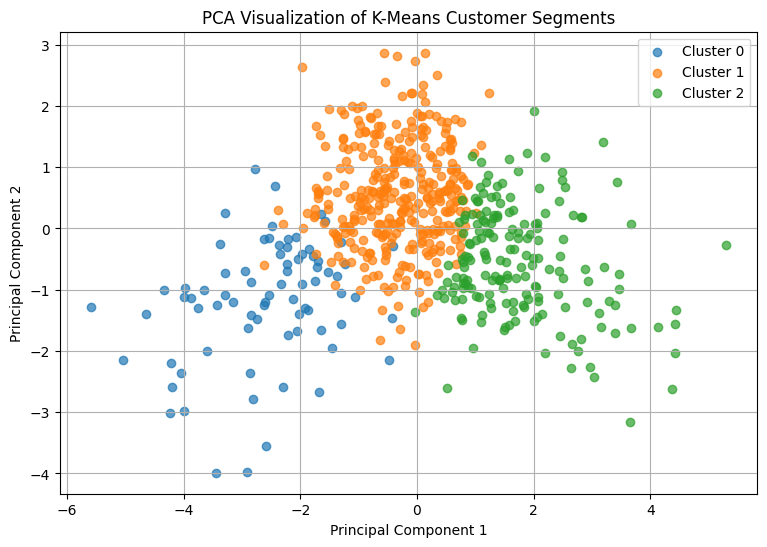

In [287]:
# Plot clusters using PC1 and PC2.
plt.figure(figsize=(9, 6))

for cluster in sorted(pca_df['Cluster'].unique()):

    cluster_data = pca_df[pca_df['Cluster'] == cluster]

    plt.scatter(
        cluster_data['PC1'],
        cluster_data['PC2'],
        label=f'Cluster {cluster}',
        alpha=0.7
    )

plt.title('PCA Visualization of K-Means Customer Segments')
plt.xlabel('Principal Component 1')
plt.ylabel('Principal Component 2')
plt.legend()
plt.grid(True)

plt.show()

In [288]:
# Apply t-SNE and compare the visualization with PCA.

from sklearn.manifold import TSNE

tsne = TSNE(
    n_components=2,
    perplexity=30, #Perplexity controls how many neighboring observations t-SNE considers when constructing the local structure. For 600 observations, 30 is a reasonable starting value.
    random_state=42,
    max_iter=1000
)

X_tsne = tsne.fit_transform(X_cluster)

print("t-SNE shape:", X_tsne.shape)

t-SNE shape: (600, 2)


In [289]:
tsne_df = pd.DataFrame(
    X_tsne,
    columns=['tSNE1', 'tSNE2']
)

tsne_df['Cluster'] = cluster_labels

tsne_df.head()

,tSNE1,tSNE2,Cluster
0,-31.806879,-0.171643,0
1,23.161442,-3.208724,2
2,27.357389,-3.280018,2
3,23.637629,1.669952,2
4,-31.816864,4.587305,0


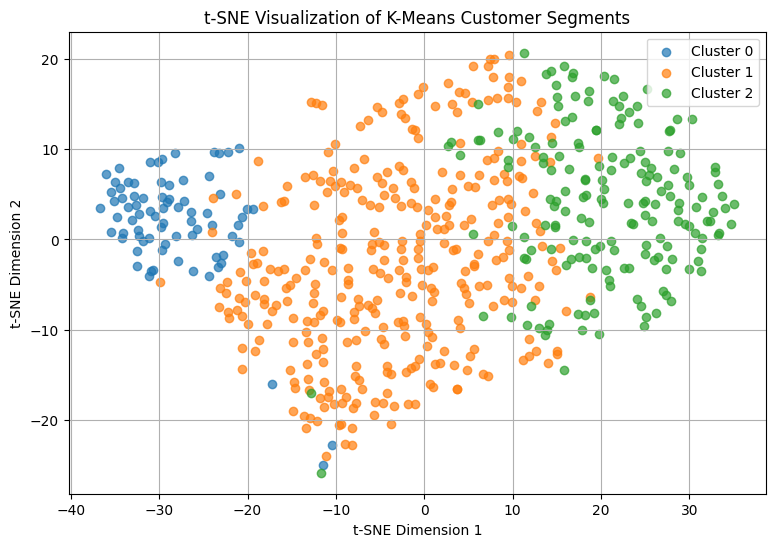

In [290]:
# plot t-SNE

plt.figure(figsize=(9, 6))

for cluster in sorted(tsne_df['Cluster'].unique()):

    cluster_data = tsne_df[tsne_df['Cluster'] == cluster]

    plt.scatter(
        cluster_data['tSNE1'],
        cluster_data['tSNE2'],
        label=f'Cluster {cluster}',
        alpha=0.7
    )

plt.title('t-SNE Visualization of K-Means Customer Segments')
plt.xlabel('t-SNE Dimension 1')
plt.ylabel('t-SNE Dimension 2')
plt.legend()
plt.grid(True)

plt.show()

In [262]:
# Which visualization is easier to interpret and why?

print("PCA and t-SNE both provide evidence of structure in the three customer segments. \nBoth shows clearer separation, particularly for Clusters 0 and 2, while Cluster 1 continues to overlap with the other groups.\nThis suggests that the segments are meaningful but not sharply separated.")

PCA and t-SNE both provide evidence of structure in the three customer segments. 
Both shows clearer separation, particularly for Clusters 0 and 2, while Cluster 1 continues to overlap with the other groups.
This suggests that the segments are meaningful but not sharply separated.


### **Part F: Supervised Learning**
HighValueCustomer was chosen for the target label as CampaignResponse is highly imbalanced.

In [263]:
# feature columns

feature_cols = [
    'Age',
    'Gender',
    'AnnualIncome',
    'SpendingScore',
    'WebsiteVisitsPerMonth',
    'AvgSessionMinutes',
    'PreviousPurchases',
    'DiscountUsed',
    'EmailOpened',
    'MembershipYears',
    'PurchaseAmount',
    'CampaignResponse'
]

X = df[feature_cols].copy()  #used original dataset df


In [264]:
# Encoding categorical columns and target
X['Gender'] = X['Gender'].map({
    'Female': 0,
    'Male': 1
})

yes_no_cols = [
    'DiscountUsed',
    'EmailOpened',
    'CampaignResponse'
]

for col in yes_no_cols:
    X[col] = X[col].map({
        'No': 0,
        'Yes': 1
    })

# Target encoding
y = df['HighValueCustomer'].map({
    'No': 0,
    'Yes': 1
})

print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (600, 12)
y shape: (600,)


In [265]:
# Split the data into training and testing sets using 80:20 split.

from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y      #target distribution in the training and testing sets should remain approximately the same.
)

print("X_train:", X_train.shape)
print("X_test :", X_test.shape)
print("y_train:", y_train.shape)
print("y_test :", y_test.shape)

X_train: (480, 12)
X_test : (120, 12)
y_train: (480,)
y_test : (120,)


In [266]:
# missing value handling
numerical_features_ml = [
    'Age',
    'AnnualIncome',
    'SpendingScore',
    'WebsiteVisitsPerMonth',
    'AvgSessionMinutes',
    'PreviousPurchases',
    'MembershipYears',
    'PurchaseAmount'
]

categorical_features_ml = [
    'Gender',
    'DiscountUsed',
    'EmailOpened',
    'CampaignResponse'
]

# Make copies
X_train_processed = X_train.copy()
X_test_processed = X_test.copy()


# Numerical columns: used median
train_medians = X_train_processed[numerical_features_ml].median()

X_train_processed[numerical_features_ml] = (
    X_train_processed[numerical_features_ml]
    .fillna(train_medians)
)

X_test_processed[numerical_features_ml] = (
    X_test_processed[numerical_features_ml]
    .fillna(train_medians)
)

# Categorical columns: used mode

train_modes = X_train_processed[categorical_features_ml].mode().iloc[0]

X_train_processed[categorical_features_ml] = (
    X_train_processed[categorical_features_ml]
    .fillna(train_modes)
)

X_test_processed[categorical_features_ml] = (
    X_test_processed[categorical_features_ml]
    .fillna(train_modes)
)

print("Missing values in X_train:")
print(X_train_processed.isnull().sum())

print("\nMissing values in X_test:")
print(X_test_processed.isnull().sum())


Missing values in X_train:
Age                      0
Gender                   0
AnnualIncome             0
SpendingScore            0
WebsiteVisitsPerMonth    0
AvgSessionMinutes        0
PreviousPurchases        0
DiscountUsed             0
EmailOpened              0
MembershipYears          0
PurchaseAmount           0
CampaignResponse         0
dtype: int64

Missing values in X_test:
Age                      0
Gender                   0
AnnualIncome             0
SpendingScore            0
WebsiteVisitsPerMonth    0
AvgSessionMinutes        0
PreviousPurchases        0
DiscountUsed             0
EmailOpened              0
MembershipYears          0
PurchaseAmount           0
CampaignResponse         0
dtype: int64


In [267]:
# scaling numerical features only. Categorical features will be ignored for scaling as they are already binary (0 and 1)
from sklearn.preprocessing import StandardScaler


scaler_ml = StandardScaler()

X_train_scaled = X_train_processed.copy()
X_test_scaled = X_test_processed.copy()

# Fit ONLY on training data
X_train_scaled[numerical_features_ml] = (
    scaler_ml.fit_transform(
        X_train_processed[numerical_features_ml]
    )
)

# Transform test data using training parameters
X_test_scaled[numerical_features_ml] = (
    scaler_ml.transform(
        X_test_processed[numerical_features_ml]
    )
)



In [268]:
# Train at least three models: Logistic Regression, Decision Tree, and KNN or Random Forest.

# Logistic Regression
from sklearn.linear_model import LogisticRegression


log_reg = LogisticRegression(
    random_state=42,
    max_iter=1000
)

# model fit
log_reg.fit(X_train_scaled, y_train)

# model predict
y_pred_lr = log_reg.predict(X_test_scaled)

# evaluation
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

accuracy_lr = accuracy_score(y_test, y_pred_lr)
precision_lr = precision_score(y_test, y_pred_lr)
recall_lr = recall_score(y_test, y_pred_lr)
f1_lr = f1_score(y_test, y_pred_lr)

print("Logistic Regression")
print("=" * 30)
print(f"Accuracy : {accuracy_lr:.4f}")
print(f"Precision: {precision_lr:.4f}")
print(f"Recall   : {recall_lr:.4f}")
print(f"F1-score : {f1_lr:.4f}")

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_lr))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_lr))


Logistic Regression
Accuracy : 0.9250
Precision: 0.9153
Recall   : 0.9310
F1-score : 0.9231

Confusion Matrix:
[[57  5]
 [ 4 54]]

Classification Report:
              precision    recall  f1-score   support

           0       0.93      0.92      0.93        62
           1       0.92      0.93      0.92        58

    accuracy                           0.93       120
   macro avg       0.92      0.93      0.92       120
weighted avg       0.93      0.93      0.93       120



In [269]:
# KNN
from sklearn.neighbors import KNeighborsClassifier

knn = KNeighborsClassifier(n_neighbors=5)

# model fit
knn.fit(X_train_scaled, y_train)

# model predict
y_pred_knn = knn.predict(X_test_scaled)

# evaluation
accuracy_knn = accuracy_score(y_test, y_pred_knn)
precision_knn = precision_score(y_test, y_pred_knn)
recall_knn = recall_score(y_test, y_pred_knn)
f1_knn = f1_score(y_test, y_pred_knn)

print("KNN")
print("=" * 30)
print(f"Accuracy : {accuracy_knn:.4f}")
print(f"Precision: {precision_knn:.4f}")
print(f"Recall   : {recall_knn:.4f}")
print(f"F1-score : {f1_knn:.4f}")

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_knn))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_knn))

KNN
Accuracy : 0.8583
Precision: 0.8596
Recall   : 0.8448
F1-score : 0.8522

Confusion Matrix:
[[54  8]
 [ 9 49]]

Classification Report:
              precision    recall  f1-score   support

           0       0.86      0.87      0.86        62
           1       0.86      0.84      0.85        58

    accuracy                           0.86       120
   macro avg       0.86      0.86      0.86       120
weighted avg       0.86      0.86      0.86       120



In [270]:
from sklearn.ensemble import RandomForestClassifier

rf = RandomForestClassifier(
    n_estimators=200,
    random_state=42,
    max_depth=5,
    n_jobs=-1
)

rf.fit(X_train_scaled, y_train)

y_pred_rf = rf.predict(X_test_scaled)

In [271]:
accuracy_rf = accuracy_score(y_test, y_pred_rf)
precision_rf = precision_score(y_test, y_pred_rf)
recall_rf = recall_score(y_test, y_pred_rf)
f1_rf = f1_score(y_test, y_pred_rf)

print("Random Forest")
print("=" * 30)
print(f"Accuracy : {accuracy_rf:.4f}")
print(f"Precision: {precision_rf:.4f}")
print(f"Recall   : {recall_rf:.4f}")
print(f"F1-score : {f1_rf:.4f}")

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_rf))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_rf))

Random Forest
Accuracy : 1.0000
Precision: 1.0000
Recall   : 1.0000
F1-score : 1.0000

Confusion Matrix:
[[62  0]
 [ 0 58]]

Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00        62
           1       1.00      1.00      1.00        58

    accuracy                           1.00       120
   macro avg       1.00      1.00      1.00       120
weighted avg       1.00      1.00      1.00       120



In [272]:
# feature importance
rf_importance = pd.Series(
    rf.feature_importances_,
    index=X_train.columns
).sort_values(ascending=False)

print(rf_importance)

PurchaseAmount           0.461859
PreviousPurchases        0.360736
MembershipYears          0.057500
SpendingScore            0.048004
AnnualIncome             0.018744
WebsiteVisitsPerMonth    0.018211
AvgSessionMinutes        0.015318
Age                      0.011691
EmailOpened              0.002752
CampaignResponse         0.002286
Gender                   0.001512
DiscountUsed             0.001386
dtype: float64


The RandomForest result of 100% is almost certainly being driven by a very simple direct relationship between HighValueCustomer and two variables: **PurchaseAmount** and **PreviousPurchases**.

In [273]:
# comparison table and the best model.

model_comparison = pd.DataFrame({
    'Model': [
        'Logistic Regression',
        'KNN',
        'Random Forest'
    ],
    'Accuracy': [
        accuracy_lr,
        accuracy_knn,
        accuracy_rf
    ],
    'Precision': [
        precision_lr,
        precision_knn,
        precision_rf
    ],
    'Recall': [
        recall_lr,
        recall_knn,
        recall_rf
    ],
    'F1-score': [
        f1_lr,
        f1_knn,
        f1_rf
    ]
})

model_comparison

,Model,Accuracy,Precision,Recall,F1-score
0,Logistic Regression,0.925000,0.915254,0.931034,0.923077
1,KNN,0.858333,0.859649,0.844828,0.852174
2,Random Forest,1.000000,1.000000,1.000000,1.000000


**Random Forest comes out as a clear winner for best predictive model having highest accuracy, precision, recall and f1-score. It is followed by Logistic regression.**

### **Part G: Prompt Engineering and Business Recommendations**
5 prompts to explain the customer segments and campaign response results.

**1. Basic Prompt:**
Explain the three customer segments identified using K-Means clustering and summarize the main characteristics of each segment.

**Response summary:**

The three segments can be described as:

1.   Cluster 0 — Low-Engagement / Developing: lower income, spending score, website activity, previous purchases, membership duration, and purchase amount.
2.   Cluster 1 — Regular / Engaged: largest segment with high spending scores and moderate engagement and purchasing activity.
3.   Cluster 2 — High-Value / Loyal: higher income, frequent visits, substantially more previous purchases, longer membership, and highest purchase amount.


**Quality rating:**
4/5

**How the prompt could be improved:**
Add the actual cluster statistics and request a concise business interpretation rather than a generic explanation.

**2. Role-Based Prompt:**
Act as a retail marketing strategist. Based on the three K-Means customer segments, explain which customer groups should receive different marketing strategies and why. Keep the recommendations practical and concise.

**Response summary:**

The three segments can be described as:

1.   Cluster 0: Use onboarding, introductory offers and engagement campaigns to encourage repeat purchases.
2.   Cluster 1: Use personalized promotions and cross-selling to increase purchase frequency and customer value.
3.   Cluster 2: Prioritize retention, loyalty rewards, premium offers and personalized experiences.


**Quality rating:**
5/5

**How the prompt could be improved:**
The role-based instruction makes the response more commercially focused and moves beyond simply describing the clusters.

**3. Step-by-Step Prompt:**
Analyze the customer segmentation step by step. First identify the main characteristics of each cluster, then compare their purchasing behavior, engagement and loyalty, and finally suggest an appropriate marketing approach for each cluster.

**Response summary:**

The three segments can be described as:

1.   **Identify:** Cluster 0 has the weakest engagement and purchasing behavior.
2.   **Compare:** Cluster 1 represents the largest regular customer group, while Cluster 2 has the strongest loyalty and purchasing activity.
3.   **Recommend:** Develop Cluster 0, engage and upsell Cluster 1, and retain/reward Cluster 2.


**Quality rating:**
5/5

**How the prompt could be improved:**
The original basic prompt can be improved by explicitly specifying the analytical sequence: **identify → compare → recommend.**

**4. Data-Driven Prompt:**
Using the following K-Means cluster statistics, identify and explain the three customer segments and recommend a suitable marketing strategy for each.
1.   Cluster 0: 77 customers, AnnualIncome ₹57,172, SpendingScore 73.47, WebsiteVisits 6.42/month, PreviousPurchases 4.22, MembershipYears 1.50, PurchaseAmount ₹410.63.
2.   Cluster 1: 344 customers, AnnualIncome ₹68,042, SpendingScore 98.85, WebsiteVisits 6.49/month, PreviousPurchases 5.94, MembershipYears 1.66, PurchaseAmount ₹543.10.
3.   Cluster 2: 179 customers, AnnualIncome ₹70,365, SpendingScore 99.82, WebsiteVisits 9.86/month, PreviousPurchases 10.85, MembershipYears 4.21, PurchaseAmount ₹592.56.

**Response summary:**

The data clearly differentiates the segments:

1.   **Cluster 0:** developing customers with low purchasing activity.
2.   **Cluster 1:** large regular/engaged customer base.
3.   **Cluster 2:** loyal high-value customers with the highest engagement and purchase history.


**Quality rating:**
5/5

**How the prompt could be improved:**

Including the **actual numerical statistics** makes the prompt much more precise and prevents the AI from making unsupported assumptions about the clusters.

**5. Business Recommendation Prompt:**

Act as a senior retail marketing consultant. Based on the customer segmentation, campaign-response analysis, and HighValueCustomer prediction results, recommend which customer segment the company should prioritize first. Explain the expected business benefit and suggest two practical actions.

**Response summary:**

**Cluster 2** — High-Value / Loyal Customers should be prioritized for retention and revenue expansion because it has the highest purchase amount, previous purchases, membership duration and website activity.

**Recommended actions:**

1.  Introduce personalized loyalty/premium offers.
2.  Use cross-selling and upselling campaigns targeted at their demonstrated purchasing interests.

Cluster 0 should receive separate development campaigns, while Cluster 1 represents the largest opportunity for scalable engagement and upselling.


**Quality rating:**
5/5

**How the prompt could be improved:**

Adding the business objective, expected benefit and requirement for actionable recommendations makes the prompt more useful than simply asking which segment is "best."

### **5 Questions**


**34. Which features are most useful for identifying high-value customers?**

The most useful features are:
1.   PurchaseAmount
2.   PreviousPurchases
3.   MembershipYears
4.   SpendingScore


**PurchaseAmount** and **PreviousPurchases** are the most useful features for identifying high-value customers, followed by MembershipYears and SpendingScore. This conclusion is arrived based on both correlation analysis and Random Forest feature importance.

**35. Do customers who opened emails have a higher campaign response rate?**

In [274]:
email_response = pd.crosstab(
    df['EmailOpened'],
    df['CampaignResponse'],
    normalize='index'
) * 100

email_response.round(2)

CampaignResponse,No,Yes
EmailOpened,,
No,14.71,85.29
Yes,5.63,94.37


Yes. Customers who opened emails had a higher campaign response rate. Among customers who opened the email, 94.37% responded to the campaign, compared with 85.29% among customers who did not open the email. This suggests that email engagement is positively associated with campaign response.

**36. Are high-income customers always high-spending customers? Support your answer using plots.**

No. High-income customers are not necessarily high-spending customers. The AnnualIncome vs SpendingScore scatter plot shows high SpendingScore values across a broad range of incomes, with no clear upward relationship. Therefore, income alone is not sufficient for identifying high-spending customers.

**37. Which customer segment should the company target first and why?**

***Target Cluster 2 — High-Value / Loyal Customers***

Cluster 2 contains 179 customers (29.8%) and has:
1.  Highest AnnualIncome = ₹70,365
2.  Highest SpendingScore = 99.82
3.  Highest website visits = 9.86/month
4.  Highest PreviousPurchases = 10.85
5.  Longest membership = 4.21 years
6.  Highest PurchaseAmount = ₹592.56

Target Cluster 2 first for retention, loyalty and upselling because these customers already demonstrate high engagement, strong purchase history and the highest purchase value.

Also, Cluster 1 is the largest segment (57.3%), so it represents the biggest scalable opportunity for converting regular customers into higher-value customers.

**38. What are the limitations of your model and clustering result?**

The clustering has relatively weak separation, as indicated by the silhouette score of 0.1817, and the dataset is limited to 600 customers. SpendingScore is highly concentrated at 100, reducing its discriminatory power.

The classification results are strong, but the 100% Random Forest performance should be interpreted cautiously because purchasing variables strongly determine the target. Finally, the models were evaluated using a single train-test split and should be validated with cross-validation.